Name:Gagan Chandra Tej
roll:2403a52222
batch:09
lab=11

In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/saicharan2003/mnist/__results__.html
/kaggle/input/notebooks/saicharan2003/mnist/__notebook_source__.ipynb
/kaggle/input/notebooks/saicharan2003/mnist/__resultx__.html
/kaggle/input/notebooks/saicharan2003/mnist/__notebook__.ipynb
/kaggle/input/notebooks/saicharan2003/mnist/__output__.json
/kaggle/input/notebooks/saicharan2003/mnist/predictions.csv
/kaggle/input/notebooks/saicharan2003/mnist/custom.css
/kaggle/input/notebooks/saicharan2003/mnist/__results___files/__results___2_1.png


Device: cpu


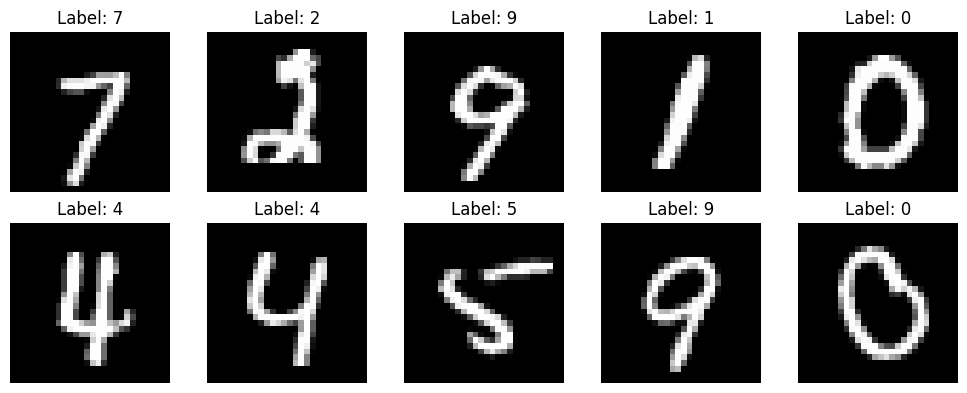

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_data = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

test_data = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = torch.utils.data.DataLoader(
    train_data, batch_size=64, shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_data, batch_size=1000, shuffle=False
)

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
class MNISTModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        return self.fc2(x)

model = MNISTModel().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5
train_losses = []
train_accuracies = []

for epoch in range(epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_losses.append(total_loss / total)
    train_accuracies.append(100 * correct / total)

    print(f"Epoch {epoch+1}/{epochs} | Loss: {train_losses[-1]:.4f} | Accuracy: {train_accuracies[-1]:.2f}%")

Epoch 1/5 | Loss: 0.1635 | Accuracy: 95.07%
Epoch 2/5 | Loss: 0.0486 | Accuracy: 98.47%
Epoch 3/5 | Loss: 0.0326 | Accuracy: 98.99%
Epoch 4/5 | Loss: 0.0248 | Accuracy: 99.20%
Epoch 5/5 | Loss: 0.0196 | Accuracy: 99.36%


Test Loss: 0.0310
Test Accuracy: 98.90%

Classification Report:

              precision    recall  f1-score   support

           0     0.9899    0.9969    0.9934       980
           1     0.9947    0.9965    0.9956      1135
           2     0.9902    0.9826    0.9864      1032
           3     0.9853    0.9950    0.9901      1010
           4     0.9949    0.9837    0.9892       982
           5     0.9899    0.9877    0.9888       892
           6     0.9906    0.9916    0.9911       958
           7     0.9733    0.9922    0.9827      1028
           8     0.9948    0.9815    0.9881       974
           9     0.9870    0.9812    0.9841      1009

    accuracy                         0.9890     10000
   macro avg     0.9891    0.9889    0.9890     10000
weighted avg     0.9890    0.9890    0.9890     10000



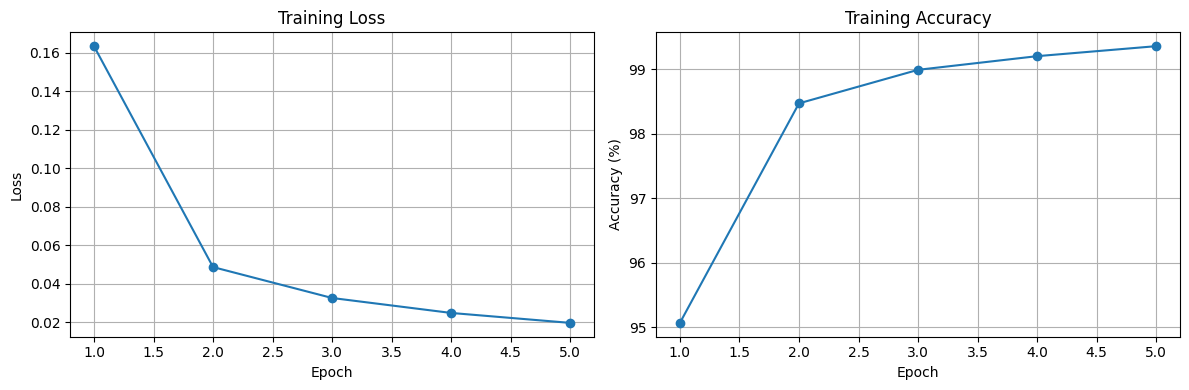

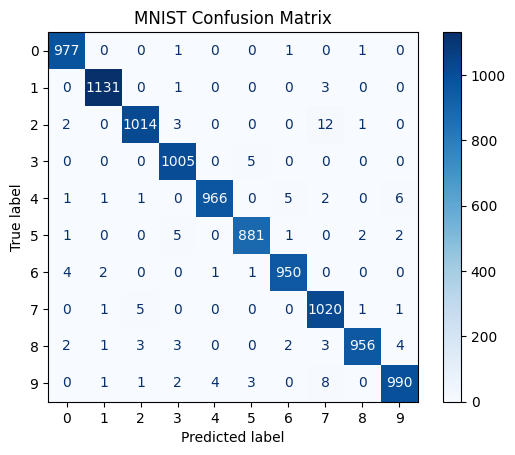

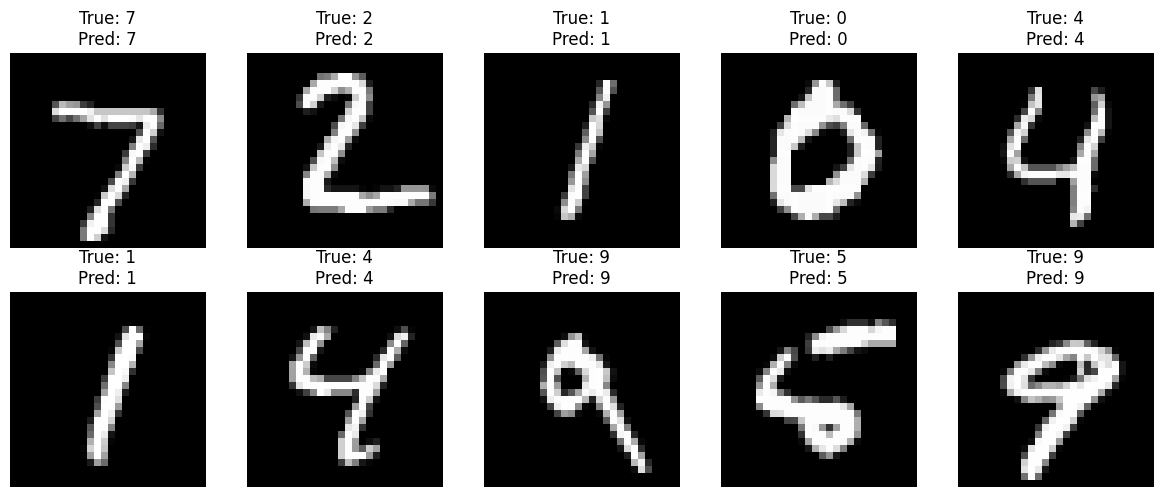

Conclusion:
The CNN model achieved 98.90% test accuracy.
The model learns handwritten digit patterns and predicts digits from 0 to 9.


In [6]:
model.eval()
all_labels = []
all_predictions = []
test_loss = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

test_loss /= len(test_data)
accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(all_labels, all_predictions, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, epochs + 1), train_losses, marker="o")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid()

axes[1].plot(range(1, epochs + 1), train_accuracies, marker="o")
axes[1].set_title("Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid()

plt.tight_layout()
plt.show()

cm = confusion_matrix(all_labels, all_predictions)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap="Blues")
plt.title("MNIST Confusion Matrix")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    image = test_data[i][0].squeeze()
    ax.imshow(image, cmap="gray")
    ax.set_title(f"True: {all_labels[i]}\nPred: {all_predictions[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Conclusion:")
print(f"The CNN model achieved {accuracy * 100:.2f}% test accuracy.")
print("The model learns handwritten digit patterns and predicts digits from 0 to 9.")